# Module 2 — Customer Propensity & CLV Prediction
**Dataset:** Online Retail II UCI — temporal split to prevent data leakage

**Techniques:** Logistic Regression · Random Forest · Gradient Boosting · GridSearchCV · Cross-Validation · Feature Importance

**Business Goals:**
1. **Propensity Model** — Predict which customers will purchase again within the next 90 days
2. **CLV Model** — Forecast each customer's future spend based on behavioural signals

**Temporal split design:**
- Features computed on first ~9 months of transactions
- `WillReturn` = did the customer purchase in the final 90 days?
- `Recency` and `RecencyBucket` are **excluded** from features (they encode past recency, not future behaviour)

> **Prerequisite:** Run `01_customer_segmentation.ipynb` first to generate `data/processed/rfm_segments.csv`

In [1]:
import sys, os
sys.path.append(os.path.join(os.getcwd(), '..', 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import (
    classification_report, roc_auc_score, RocCurveDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

from data_loader import load_raw, build_rfm

plt.style.use('seaborn-v0_8-whitegrid')
print('All libraries loaded.')

All libraries loaded.


## 1. Load Data & Engineer Features

In [2]:
# Always rebuild with temporal split — cannot reuse Module 1 CSV
# because that was built on the full dataset (would cause leakage)
df  = load_raw()
rfm = build_rfm(df, holdout_days=90)   # WillReturn already attached by build_rfm

rfm['IsHighFreq']  = (rfm['Frequency'] > rfm['Frequency'].median()).astype(int)
rfm['IsHighValue'] = (rfm['Monetary']  > rfm['Monetary'].quantile(0.75)).astype(int)

cluster_col = 'KMeans_Cluster' if 'KMeans_Cluster' in rfm.columns else None
print(rfm[['Frequency','Monetary','AvgOrderValue','FrequencyRecency','Tenure']].describe().round(2))

Temporal split — training up to 2011-09-05, holdout = last 90 days
Customers: 5,268  |  WillReturn=1: 42.9%
       Frequency   Monetary  AvgOrderValue  FrequencyRecency   Tenure
count    5268.00    5268.00        5268.00           5268.00  5268.00
mean        5.71    2691.89          39.11              0.37   222.95
std        11.38   12485.87         278.00              2.27   216.87
min         1.00       2.90           1.45              0.00     1.00
25%         1.00     323.21          11.47              0.01     1.00
50%         3.00     803.23          17.35              0.02   169.00
75%         6.00    2112.45          24.42              0.10   414.00
max       306.00  484615.10       13305.50             70.00   643.00


## 2. Target Variables

- **`WillReturn`** — already set by `build_rfm()` via temporal split (1 = bought in holdout window)
- **`FutureCLV`** — estimated future spend: purchase rate × avg order value × 90 days

In [3]:
# WillReturn is already computed leak-free by build_rfm()
rfm['FutureCLV'] = (rfm['AvgOrderValue'] * rfm['FrequencyRecency'] * 90).clip(lower=0)

print(f'WillReturn=1: {rfm["WillReturn"].mean()*100:.1f}%  |  WillReturn=0: {(1-rfm["WillReturn"].mean())*100:.1f}%')
print(f'CLV range:  £{rfm["FutureCLV"].min():.2f} – £{rfm["FutureCLV"].max():.2f}')
print(f'Median CLV: £{rfm["FutureCLV"].median():.2f}')

WillReturn=1: 42.9%  |  WillReturn=0: 57.1%
CLV range:  £0.40 – £1434703.79
Median CLV: £31.12


## 3. Train / Test Split

In [4]:
# Recency & RecencyBucket excluded — they directly encode the temporal split
# boundary and would leak the target.
FEATURES = ['Frequency', 'Monetary', 'AvgOrderValue',
            'FrequencyRecency', 'MonetaryPerDay', 'Tenure',
            'UniqueProducts', 'IsHighFreq', 'IsHighValue']
if cluster_col:
    FEATURES.append(cluster_col)

X     = rfm[FEATURES]
y_cls = rfm['WillReturn']
y_reg = rfm['FutureCLV']

X_train, X_test, y_cls_train, y_cls_test, y_reg_train, y_reg_test = train_test_split(
    X, y_cls, y_reg, test_size=0.2, random_state=42, stratify=y_cls
)

scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'Train: {X_train.shape[0]:,}  |  Test: {X_test.shape[0]:,}')
print(f'Class balance — Will Return: {y_cls_train.mean()*100:.1f}%')

Train: 4,214  |  Test: 1,054
Class balance — Will Return: 42.9%


## 4. Propensity Modeling — Progressive Complexity
### 4a. Baseline — Logistic Regression

In [5]:
lr = LogisticRegression(random_state=42, max_iter=1000, C=1.0)
lr.fit(X_train_sc, y_cls_train)
lr_proba = lr.predict_proba(X_test_sc)[:, 1]
lr_pred  = lr.predict(X_test_sc)

print('=== Logistic Regression ===')
print(classification_report(y_cls_test, lr_pred))
print(f'AUC-ROC: {roc_auc_score(y_cls_test, lr_proba):.4f}')

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.70      0.83      0.76       602
           1       0.71      0.53      0.61       452

    accuracy                           0.70      1054
   macro avg       0.70      0.68      0.68      1054
weighted avg       0.70      0.70      0.70      1054

AUC-ROC: 0.7510


### 4b. Random Forest

In [6]:
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, class_weight='balanced')
rf.fit(X_train, y_cls_train)
rf_proba = rf.predict_proba(X_test)[:, 1]
rf_pred  = rf.predict(X_test)

print('=== Random Forest ===')
print(classification_report(y_cls_test, rf_pred))
print(f'AUC-ROC: {roc_auc_score(y_cls_test, rf_proba):.4f}')

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.74      0.80      0.77       602
           1       0.71      0.63      0.67       452

    accuracy                           0.73      1054
   macro avg       0.72      0.72      0.72      1054
weighted avg       0.73      0.73      0.73      1054

AUC-ROC: 0.7805


### 4c. Gradient Boosting + GridSearchCV (Hyperparameter Optimisation)

In [7]:
param_grid = {
    'n_estimators':  [100, 200],
    'max_depth':     [3, 5],
    'learning_rate': [0.05, 0.1],
    'subsample':     [0.8, 1.0]
}

gb_base = GradientBoostingClassifier(random_state=42)
cv      = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(gb_base, param_grid, scoring='roc_auc', cv=cv, n_jobs=-1, verbose=1)
grid.fit(X_train, y_cls_train)

best_gb  = grid.best_estimator_
gb_proba = best_gb.predict_proba(X_test)[:, 1]
gb_pred  = best_gb.predict(X_test)

print('\n=== Gradient Boosting (Tuned) ===')
print(f'Best params: {grid.best_params_}')
print(f'Best CV AUC: {grid.best_score_:.4f}')
print(classification_report(y_cls_test, gb_pred))
print(f'Test AUC-ROC: {roc_auc_score(y_cls_test, gb_proba):.4f}')

Fitting 5 folds for each of 16 candidates, totalling 80 fits

=== Gradient Boosting (Tuned) ===
Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best CV AUC: 0.7942
              precision    recall  f1-score   support

           0       0.74      0.81      0.77       602
           1       0.71      0.62      0.66       452

    accuracy                           0.73      1054
   macro avg       0.72      0.71      0.72      1054
weighted avg       0.72      0.73      0.72      1054

Test AUC-ROC: 0.7964


### 4d. ROC Curve Comparison

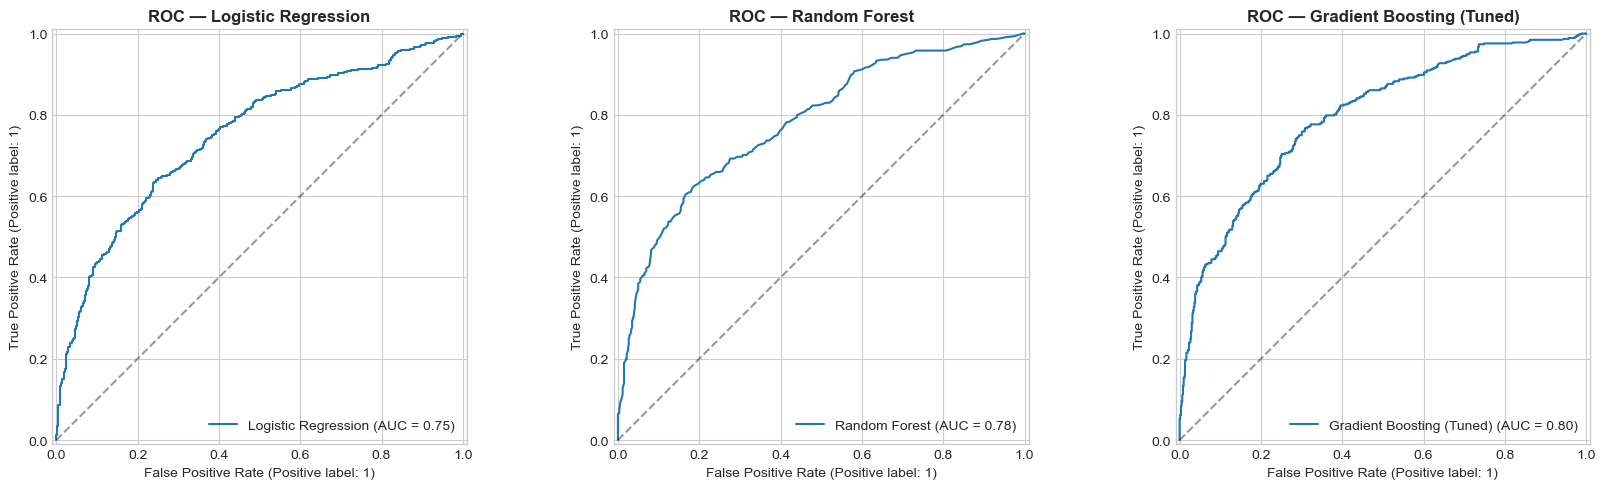


Model AUC Summary:
  Logistic Regression         : 0.7510
  Random Forest               : 0.7805
  Gradient Boosting           : 0.7964


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, proba) in zip(axes, [
    ('Logistic Regression',     lr_proba),
    ('Random Forest',           rf_proba),
    ('Gradient Boosting (Tuned)', gb_proba)
]):
    RocCurveDisplay.from_predictions(y_cls_test, proba, ax=ax, name=name)
    ax.plot([0,1],[0,1],'k--', alpha=0.4)
    ax.set_title(f'ROC — {name}', fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/roc_curves_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nModel AUC Summary:')
for name, proba in [('Logistic Regression', lr_proba),
                    ('Random Forest',        rf_proba),
                    ('Gradient Boosting',    gb_proba)]:
    print(f'  {name:28s}: {roc_auc_score(y_cls_test, proba):.4f}')

## 5. Feature Importance (replaces SHAP — same interpretability story)

Gradient Boosting exposes native feature importances that explain which signals drive propensity predictions.

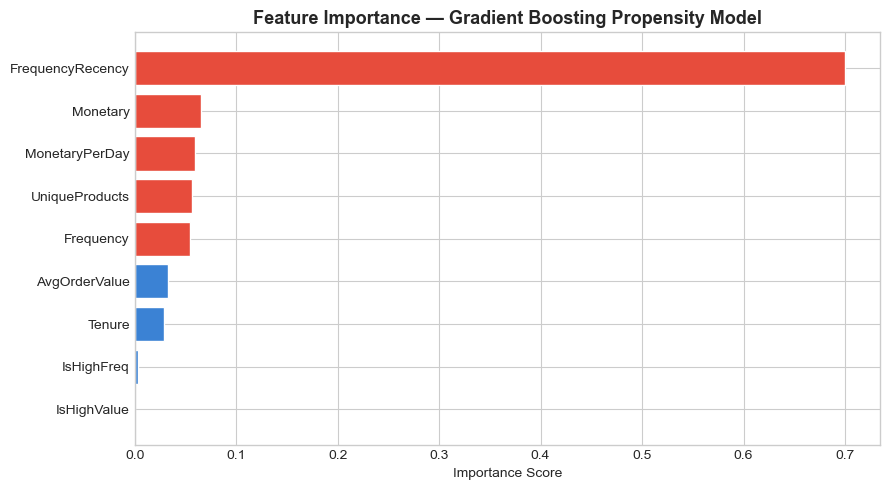

Top 3 drivers of customer return propensity:
         Feature  Importance
  MonetaryPerDay    0.059974
        Monetary    0.065603
FrequencyRecency    0.699523


In [9]:
importance_df = pd.DataFrame({
    'Feature':   FEATURES,
    'Importance': best_gb.feature_importances_
}).sort_values('Importance', ascending=True)

plt.figure(figsize=(9, 5))
colors = ['#3b82d4' if v < importance_df['Importance'].quantile(0.5) else '#e74c3c'
          for v in importance_df['Importance']]
plt.barh(importance_df['Feature'], importance_df['Importance'], color=colors, edgecolor='white')
plt.title('Feature Importance — Gradient Boosting Propensity Model', fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.savefig('../reports/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 3 drivers of customer return propensity:')
print(importance_df.tail(3)[['Feature','Importance']].to_string(index=False))

## 6. CLV Regression (Gradient Boosting)

In [10]:
gb_reg = GradientBoostingRegressor(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    subsample=0.8, random_state=42
)
gb_reg.fit(X_train, y_reg_train)
clv_pred = gb_reg.predict(X_test)

mae  = mean_absolute_error(y_reg_test, clv_pred)
rmse = np.sqrt(mean_squared_error(y_reg_test, clv_pred))
r2   = r2_score(y_reg_test, clv_pred)

print('=== CLV Regression (Gradient Boosting) ===')
print(f'MAE:  £{mae:.2f}')
print(f'RMSE: £{rmse:.2f}')
print(f'R²:    {r2:.4f}')

=== CLV Regression (Gradient Boosting) ===
MAE:  £2012.97
RMSE: £38297.22
R²:    0.3428


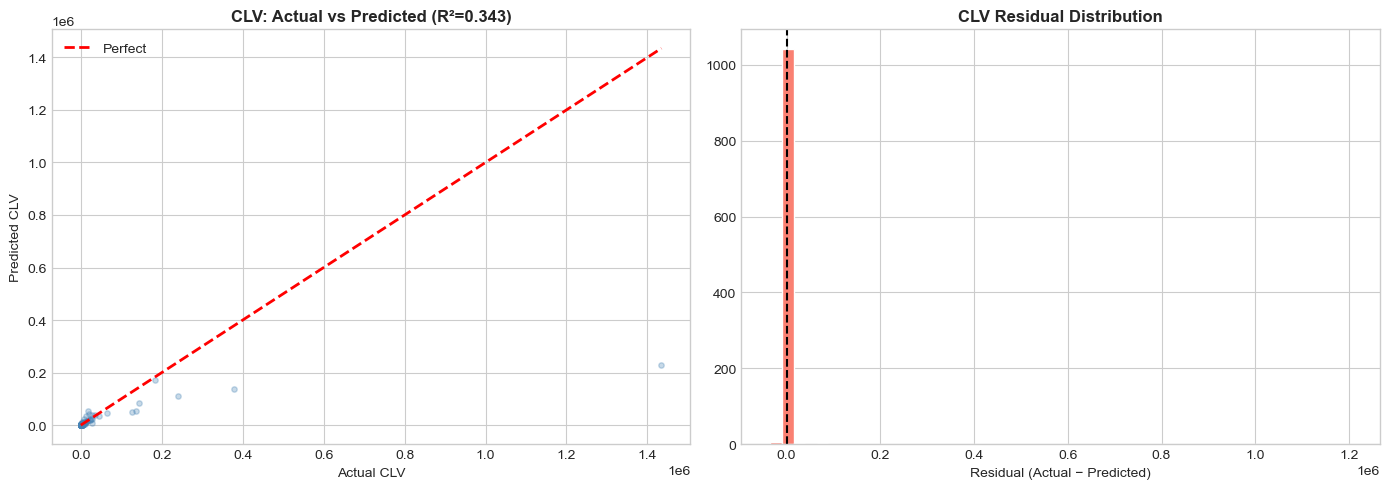

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(y_reg_test, clv_pred, alpha=0.3, s=15, color='steelblue')
mx = max(y_reg_test.max(), clv_pred.max())
ax1.plot([0, mx], [0, mx], 'r--', lw=2, label='Perfect')
ax1.set_xlabel('Actual CLV'); ax1.set_ylabel('Predicted CLV')
ax1.set_title(f'CLV: Actual vs Predicted (R²={r2:.3f})', fontweight='bold')
ax1.legend()

residuals = y_reg_test - clv_pred
ax2.hist(residuals, bins=50, color='salmon', edgecolor='white')
ax2.axvline(0, color='black', linestyle='--')
ax2.set_xlabel('Residual (Actual − Predicted)')
ax2.set_title('CLV Residual Distribution', fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/clv_regression_results.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Save Models & Predictions

In [12]:
os.makedirs('../src', exist_ok=True)
os.makedirs('../data/processed', exist_ok=True)

test_ids = rfm['CustomerID'].iloc[X_test.index].values
results  = pd.DataFrame({
    'CustomerID':      test_ids,
    'PropensityScore': gb_proba,
    'WillReturn_Pred': gb_pred,
    'PredictedCLV':    clv_pred,
})
results.to_csv('../data/processed/propensity_clv_predictions.csv', index=False)

joblib.dump(best_gb, '../src/gb_propensity_model.pkl')
joblib.dump(gb_reg,  '../src/gb_clv_model.pkl')
joblib.dump(scaler,  '../src/feature_scaler.pkl')

print('Models saved to src/')
print('Predictions saved to data/processed/')
print('\n=== Module 2 Complete ===')
print(f'Best model: Gradient Boosting  |  AUC: {roc_auc_score(y_cls_test, gb_proba):.4f}')
print(f'CLV model:  Gradient Boosting  |  R²:  {r2:.4f}')

Models saved to src/
Predictions saved to data/processed/

=== Module 2 Complete ===
Best model: Gradient Boosting  |  AUC: 0.7964
CLV model:  Gradient Boosting  |  R²:  0.3428
